# 04 · Catchment water balance (Thornthwaite–Mather)

$$P = H + AET + \Delta S$$

Monthly model (sheet eqs. 4–7), all in mm, $0 \le S \le S_{max}$, $L_0 = 0$, $S_0 = 0$:

- wet month ($P \ge PET$): $L = 0$, $S_t = \min(S_{t-1} + P - PET,\ S_{max})$, $AET = PET$
- dry month ($P < PET$): $L_t = L_{t-1} + (P - PET)$, $S_t = S_{t-1}\exp(L_t/S_{max})$, $AET = \min[PET,\ P + S_{t-1} - S_t]$
- $H_t = \max[P - PET - (S_t - S_{t-1}),\ 0]$

Inflow to the reservoir: $Q_{in} = H \cdot A_c$ (1 mm × 1 km² = 10³ m³ = 10⁻³ hm³).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [2]:
from epss.soil import thornthwaite_mather

clim = pd.read_csv(PROC / "climate.csv", index_col=0, parse_dates=True)
pet = pd.read_csv(PROC / "pet.csv", index_col=0, parse_dates=True).iloc[:, 0]
tm = thornthwaite_mather(clim.p_mm, pet, case["smax_mm"])
tm.head(12).round(1)

,p,pet,deficit,aet,soil,runoff
1981-01-01,3.6,43.4,-39.8,3.6,0.0,0.0
1981-02-01,24.6,51.0,-66.3,24.6,0.0,0.0
1981-03-01,44.2,81.0,-103.0,44.2,0.0,0.0
1981-04-01,87.4,89.3,-104.9,87.4,0.0,0.0
1981-05-01,23.9,128.3,-209.2,23.9,0.0,0.0
1981-06-01,7.6,180.6,-382.2,7.6,0.0,0.0
1981-07-01,4.4,198.5,-576.3,4.4,0.0,0.0
1981-08-01,1.8,170.2,-744.6,1.8,0.0,0.0
1981-09-01,21.0,116.9,-840.5,21.0,0.0,0.0
1981-10-01,26.1,79.6,-894.0,26.1,0.0,0.0


Check that the balance closes every month.

In [3]:
# TODO: Monthly balance error P - (H + AET + dS), with dS = S(t) - S(t-1) and S0 = 0.
# In: tm (DataFrame from thornthwaite_mather)
# Out: error (pd.Series, mm)
dS = tm.soil - tm.soil.shift(1, fill_value=0)      # S(t) - S(t-1), with S0 = 0
error = tm.p - (tm.runoff + tm.aet + dS)
print(f"max |P - (H + AET + dS)| = {error.abs().max():.2e} mm")

max |P - (H + AET + dS)| = 2.84e-14 mm


{'p': 518.0, 'pet': 1216.0, 'aet': 443.0, 'runoff': 74.0} H/P = 0.14


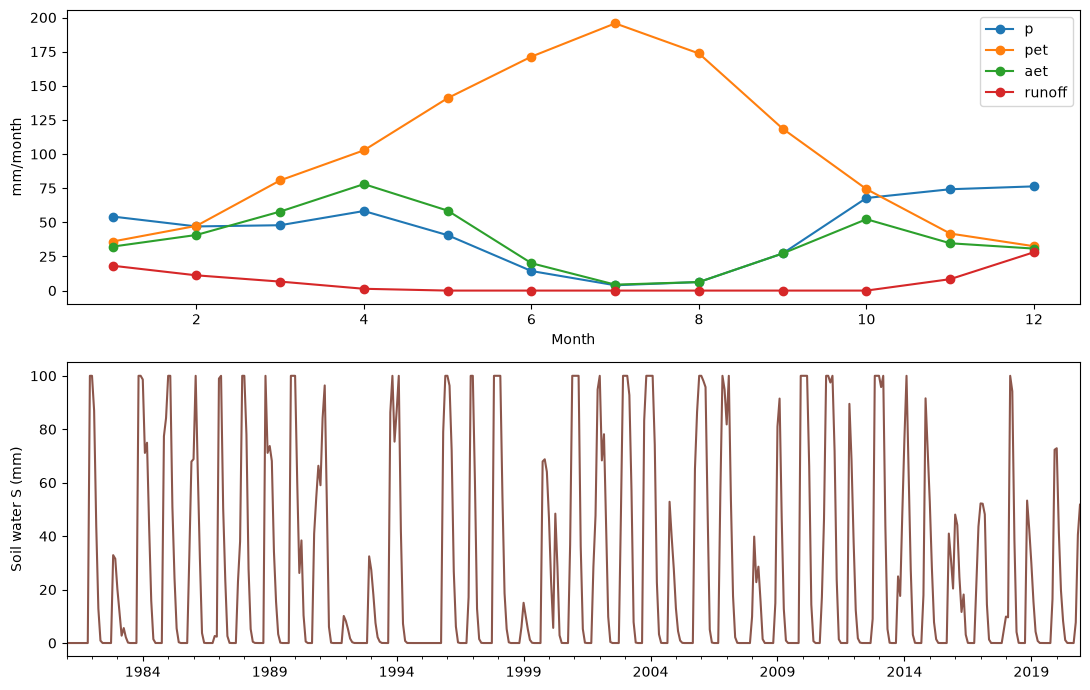

In [4]:
annual = tm[["p", "pet", "aet", "runoff"]].groupby(tm.index.year).sum()
print(annual.mean().round(0).to_dict(), f"H/P = {annual.runoff.mean() / annual.p.mean():.2f}")

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
tm[["p", "pet", "aet", "runoff"]].groupby(tm.index.month).mean().plot(ax=ax[0], marker="o")
ax[0].set_xlabel("Month"); ax[0].set_ylabel("mm/month")
tm.soil.plot(ax=ax[1], color="tab:brown")
ax[1].set_ylabel("Soil water S (mm)")
plt.tight_layout()

Mean inflow 4.08 hm³/year (min 0.00, max 18.22)


Text(0.5, 0, 'Year')

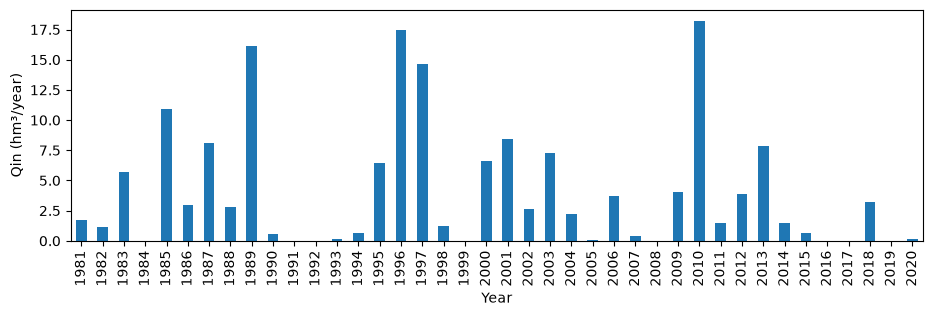

In [5]:
# TODO: Inflow to the reservoir, sheet eq. (8): Qin = H * Ac; mm x km² / 1000 = hm³.
# In: tm.runoff (mm/month), case['catchment_area_km2']
# Out: inflow (pd.Series, hm³/month)
inflow = (tm.runoff * case["catchment_area_km2"] / 1000).rename("inflow")
tm.assign(inflow=inflow).to_csv(PROC / "catchment.csv")
annual_q = inflow.groupby(inflow.index.year).sum()
print(f"Mean inflow {annual_q.mean():.2f} hm³/year (min {annual_q.min():.2f}, max {annual_q.max():.2f})")
ax = annual_q.plot.bar(figsize=(11, 3)); ax.set_ylabel("Qin (hm³/year)"); ax.set_xlabel("Year")

**Answer.**

*Your answer here.*